# Cooling timescales: line integrals and nearest XY columns

**Main conclusion:** use direct vertical lines for quantitative 1D profiles.
For $t_c$ and $\tau$, the library and dense line integrals agree closely; the larger differences in
the current profiles come from XY snapping and coarse vertical sampling.
The default $Z_{\max}=10r_p$ is ample for $t_c$ in both tested snapshots, but
absolute $H$, $t_v$ and $t_{\rm es}$ retain a measurable Z-limit dependence,
especially in the late $10^4\,M_\odot$ snapshot.

We tested **81 fixed streamline samples per snapshot**: $10^5\,M_\odot$,
snapshot 200 at $0.999t_{\rm fb}$, and $10^4\,M_\odot$, snapshot 151 at
$2.175t_{\rm fb}$. Percentiles below give equal weight to these rays.

| Test: absolute fractional difference, 90th percentile | $10^5\,M_\odot$ | $10^4\,M_\odot$ |
|---|---:|---:|
| Current $256^2\times512$ columns vs direct lines: $t_c$ | 19.21% | 12.14% |
| Current columns vs direct lines: $t_v$ | 11.91% | 9.19% |
| Current columns vs direct lines: $t_{\rm es}$ | 12.53% | 11.95% |
| Adaptive library vs dense line: $t_c$ | 0.45% | 0.52% |
| Adaptive library vs dense line: $\tau$ | 1.08% | 0.93% |
| Extending $10\to20r_p$: $t_{\rm es}$ | 0.98% | 6.70% |
| Extending $10\to40r_p$: $t_{\rm es}$ | 2.55% | 12.93% |

- **Sampling matters more than the choice of integrator.** Typical current/direct
  differences are only 3–4%, but individual locations can differ much more
  (maximum $t_c$ difference 167% in the $10^5$ case). XY snapping dominates there;
  both XY and vertical sampling matter in the $10^4$ case. Refining XY from 256
  to 1024 reduces its $t_c$ p90 difference from 26.0% to 7.2%, and from 11.4%
  to 2.5%, respectively. Convergence need not be monotonic at individual rays.
- **Increasing `NZ` alone is not a central-resolution test.** Keeping
  `DZ_MIDPLANE=0.1` leaves the errors almost unchanged. Refining the same sinh
  grid shape reduces its midplane spacing. The 8192-interval midpoint reference
  has $\Delta z_{\min}\simeq0.00625$ code length; doubling to 16384 changes all
  three timescales by at most 0.55% at p90 (maximum 2.66%). Adaptive checks use
  cell fractions $1/4,1/8,1/16$; the table reports $1/16$.
- **The Z-limit sensitivity is in the height moment.** Going from $10$ to
  $40r_p$ changes $t_c$ by less than 0.004% on every tested ray, while the median
  $t_{\rm es}$ increases by 0.76% and 8.45%, with maxima 3.98% and 14.31%.
  Optical depths change by at most 0.009% and 0.131%; the extra dilute material
  instead contributes to $\int\rho|z|dz$. In the $10^4$ case, $20\to40r_p$
  still changes $t_{\rm es}$ by 5.77% at p90: even $20r_p$ is not a strict
  saturation limit for the absolute height-based times. Restoring the legacy
  grid's omitted positive-Z interval alone changes any timescale by less than
  0.12%, so that endpoint issue does not explain the larger differences.
- **The physical ordering is robust in this test.** Every sampled ray has
  $\max(t_c,t_{\rm es})/t_v>1$ at every tested limit; median ratios at $10r_p$
  are about 21 and 615. Since $t_{\rm es}/t_v=\tau\overline{|v_z|}/c$, the
  common $H$ cancels. Extending $10\to40r_p$ changes this ratio by at most
  0.11% and 0.69% on individual rays. This strengthens the picture of rapid local emission
  with slower photon escape relative to vertical motion in these columns.
  These proxies do not themselves measure net radiative energy loss.

For these 1D profiles, direct XY lines avoid the extra grid-snapping error.
Use a genuinely refined Z grid (4096–8192 intervals here) and state the Z limit
when quoting absolute height-based times; retaining $10r_p$ is well supported
for emission times and the qualitative escape/flow ordering. The cells below
separate each effect and retain the figures, exact grids, and numerical checks.


## Definitions and controlled comparisons

The question is whether snapping a streamline point to a projected XY column,
vertical quadrature, or the finite vertical limit changes the cooling diagnostic.
We preserve [the current helper's](cooling_profile_helpers.py) definitions:

$$\Sigma=\int\rho\,dz,\quad H=\frac{\int\rho|z|\,dz}{\Sigma},\quad
\bar v_z=\frac{\int\rho|v_z|\,dz}{\Sigma},$$
$$t_c=\frac{\int\rho\epsilon_{\rm th}\,dz}
{\int\alpha_P a_{\rm rad}T^4c\,dz},\qquad
t_v=H/\bar v_z,\qquad
\tau=\tfrac12\int\alpha_R\,dz,\qquad t_{\rm es}=H\tau/c.$$

Here $\alpha_{P,R}$ are extinction coefficients (inverse length), not opacity
per mass, and $|z|$ is the **query height**, not the nearest cell-center height.
The emission time is gross thermal emission; the escape time is the existing
diffusion proxy. We do not replace $H$ by a photosphere height in this test.

All field evaluations use the same full native-cell KD tree, with nearest-neighbor
sampling and no density cut or smooth interpolation. The current method snaps
native streamline cell centers to the nearest XY grid nodes, then uses left
endpoint sums in Z (255 usable XY nodes per axis and 511 Z intervals at the
default settings). We query only these columns: this is equivalent to selecting
them from the full 3D grid. Its `endpoint=False` grid omits the last positive-Z
interval; actual integrated bounds are printed below.

Direct lines retain the same native streamline centers' XY coordinates. Dense
midpoint sums provide all moments above. Independently, `richio.analysis.integrate_optical_depth`
uses adaptive steps bounded by $fV^{1/3}$ at both endpoints, with trapezoids and
linear within-step quadrature. It does not trace exact Voronoi faces. With
`target_tau=None, max_delta_tau=None`, the step mesh depends on cell size alone.
For an additional library check of $t_c$, we integrate positive energy and emission
fields after normalizing each to inverse length:
$\int F dz=F_0 L_0\int[F/(F_0L_0)]dz$. This changes no physical definition.
Adaptive escape times use the dense-line $H$, so this independently tests $\tau$,
not the height quadrature.

The seed is the densest native cell with $0\le x\le2r_p$,
$|y|,|z|\le r_p$ and spherical $r\ge0.7r_p$. The frozen-snapshot streamline
follows nearest-cell velocities with midpoint time stepping, maximum spatial
step $0.05R_\odot$, and 961 output times spaced by 1.25 s. Consecutive visits
to the same native cell are collapsed as in the profile helper.

Tests use fixed samples nearest to 81 equally spaced elapsed times over
$[-600,600]$ s, plus the seed. Repeated selected indices are removed. Reported
median, 90th-percentile and maximum absolute fractional differences give **equal
weight to these sampled rays**; they are not mass- or dissipation-weighted statistics.
Resolution here means analysis sampling, not a rerun at different native resolution.
Each run section is independent after the common setup.

In [1]:
%matplotlib inline

import importlib
import os
import sys

ROOT = "/home/hey4/rich_tde"
os.environ["MPLCONFIGDIR"] = os.path.join(ROOT, ".cache/matplotlib")
os.makedirs(os.environ["MPLCONFIGDIR"], exist_ok=True)
sys.path.insert(0, os.path.join(ROOT, "dev"))
sys.path.insert(0, os.path.join(ROOT, "works/cooling-checks"))

In [2]:
import dev  # isort: skip

importlib.reload(dev)  # Reapply the repository style when rerunning setup.

<module 'dev' from '/home/hey4/rich_tde/dev/dev/__init__.py'>

In [3]:
import cooling_profile_helpers as cooling
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import unyt as u
from IPython.display import display
from richio.data import _grid_axis, _sinh_scale_from_spacing
from scipy.spatial import cKDTree

import richio

WORKERS = 8
cooling.WORKERS = WORKERS
N_TIME_SAMPLES = 81
NXY_DEFAULT, NZ_DEFAULT = 256, 512
DZ_DEFAULT = 0.1 * richio.units.lscale
Z_DEFAULT_RP = 10
NXY_VALUES = [128, 256, 512, 1024]
NZ_INTERVALS = [256, 512, 1024, 2048, 4096, 8192]
N_REFERENCE = 8192
CELL_FRACTIONS = [0.25, 0.125, 0.0625]
Z_LIMITS_RP = [2, 5, 10, 20, 40]
A_RAD = 4 * u.stefan_boltzmann_constant / u.c
TIME_FIELDS = ["tc", "tv", "tes"]
TIME_LABELS = [r"$t_c$", r"$t_v$", r"$t_{\rm es}$"]
COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"]
SUMMARIES = {}
print("dev:", dev.__file__)
print("richio:", richio.__file__)

dev: /home/hey4/rich_tde/dev/dev/__init__.py
richio: /zfsstore/user/hey4/rich_tde/richio/richio/__init__.py


In [4]:
def integrate_columns(xy, edges, rule="midpoint"):
    """Reuse one explicit line quadrature for all experiments; return only moments.

    The native fields/tree belong to the current run section. Coordinate values
    are stripped only at SciPy's KD-tree boundary. No 3D grid is allocated.
    """
    z = edges[:-1] if rule == "left" else 0.5 * (edges[:-1] + edges[1:])
    dz = np.diff(edges)
    points = u.unyt_array(np.empty((len(xy), len(z), 3)), xy.units)
    points[..., :2] = xy[:, None, :]
    points[..., 2] = z
    ids = tree.query(points.to_value("code_length"), workers=WORKERS)[1]
    rho = fields["density"][ids]
    sigma = np.sum(rho * dz, axis=1)
    moment_z = np.sum(rho * np.abs(z) * dz, axis=1)
    moment_v = np.sum(rho * np.abs(fields["velocity"][ids, 2]) * dz, axis=1)
    energy = np.sum(internal[ids] * dz, axis=1)
    emission = np.sum(emissivity[ids] * dz, axis=1)
    tau = (0.5 * np.sum(alpha[ids] * dz, axis=1)).to("dimensionless")
    height = moment_z / sigma
    return {
        "tc": (energy / emission).to("s"),
        "tv": (moment_z / moment_v).to("s"),
        "tes": (height * tau / u.c).to("s"),
        "H": height.to("Rsun"),
        "tes/tv": (tau * moment_v / (sigma * u.c)).to("dimensionless"),
        "tau": tau,
        "sigma": sigma.to("g/cm**2"),
        "energy": energy.to("erg/cm**2"),
        "emission": emission.to("erg/(cm**2*s)"),
    }


def snapped_xy(xy, nxy):
    """Match the helper's xspace[:-1], yspace[:-1] nearest-column choice."""
    axis = np.linspace(-XY, XY, nxy, endpoint=False)[:-1]
    return np.column_stack(
        [
            axis[np.asarray(np.abs(xy[:, j, None] - axis).argmin(axis=1))]
            for j in range(2)
        ]
    )


def comparison_rows(label, result, reference, names=TIME_FIELDS):
    """Plain numbers only at the displayed-table boundary; equal ray weights."""
    rows = []
    for name in names:
        difference = 100 * np.abs(
            (result[name] / reference[name] - 1).to_value("dimensionless")
        )
        assert np.all(np.isfinite(difference)), (label, name)
        rows.append(
            {
                "comparison": label,
                "quantity": name,
                "median %": np.median(difference),
                "p90 %": np.percentile(difference, 90),
                "max %": difference.max(),
            }
        )
    return rows

## 1e5: snapshot 200

In [5]:
RUN = "1e5"
SNAPSHOT = 200
SNAPSHOT_PATH = "/data1/projects/pi-rossiem/TDE_data/YujieSnellius/R0.47M0.5BH100000beta1S60n1.5ComptonHiResNewAMR/snap_full_200.h5"
XY = 100 * richio.units.lscale
RSTAR = 0.47 * richio.units.lscale
MSTAR = 0.5 * richio.units.mscale
MBH = 1e5 * richio.units.mscale
RP = RSTAR * (MBH / MSTAR) ** (1 / 3)
t_fb = dev.TDEBasics(MBH, MSTAR, RSTAR).t_fb
snap = richio.load(SNAPSHOT_PATH)
print(SNAPSHOT_PATH)
print("Time:", snap.time.to("day"), "t/tfb:", (snap.time / t_fb).to("dimensionless"))
print("rp:", RP.to("Rsun"), "XY bounds:", -XY, XY)

# Only the fields needed here; all coordinates follow the source notebook.
fields = {
    "position": np.column_stack([snap.X, snap.Y, snap.Z]),
    "velocity": np.column_stack([snap.vx, snap.vy, snap.vz]),
    "density": snap.rho,
    "volume": snap.volume,
}
tree = cKDTree(fields["position"].to_value("code_length"))
seed = cooling.get_max_density_cell(fields, RP.to_value("code_length"))
streamline = cooling.get_streamline(fields, seed, tree)
requested_time = np.linspace(-600, 600, N_TIME_SAMPLES) * u.s
# unyt retains units on argmin indices; indexing itself requires plain integers.
selected = np.unique(
    np.r_[
        np.asarray(np.abs(streamline["time"][:, None] - requested_time).argmin(axis=0)),
        np.flatnonzero(streamline["indices"] == seed),
    ]
)
times = streamline["time"][selected]
exact_xy = streamline["positions"][selected, :2]
assert np.all(np.abs(exact_xy) < XY)
temperature = snap.T
internal = fields["density"] * snap.sie
alpha = richio.opacity.rosseland_alpha(temperature, fields["density"])
emissivity = (
    richio.opacity.planck_alpha(temperature, fields["density"])
    * A_RAD
    * temperature**4
    * u.c
)
del temperature
Z = Z_DEFAULT_RP * RP
z_legacy = _grid_axis(
    -Z, Z, NZ_DEFAULT, "sinh", None, endpoint=False, central_spacing=DZ_DEFAULT
)
sinh_scale = _sinh_scale_from_spacing(-Z, Z, NZ_DEFAULT, DZ_DEFAULT, endpoint=False)
z_reference = _grid_axis(-Z, Z, N_REFERENCE + 1, "sinh", sinh_scale, endpoint=True)
grid_xy = snapped_xy(exact_xy, NXY_DEFAULT)
print("Native cells:", len(fields["density"]), "selected rays:", len(selected))
print(
    "Seed:",
    seed,
    "position:",
    fields["position"][seed],
    "density:",
    fields["density"][seed],
)
print(
    "Trace: midpoint dx/dt=v, 961 output times, 1.25 s spacing; max spatial step",
    cooling.MAX_LSTEP,
)
print(
    "Legacy grid:",
    (NXY_DEFAULT, NXY_DEFAULT, NZ_DEFAULT),
    "XY spacing:",
    2 * XY / NXY_DEFAULT,
)
print(
    "Legacy actual Z/rp:",
    z_legacy[[0, -1]] / RP,
    "min/max dz:",
    np.diff(z_legacy).min(),
    np.diff(z_legacy).max(),
)
print("Reference: exact XY;", N_REFERENCE, "midpoint intervals; Z/rp=+/-", Z_DEFAULT_RP)
print(
    "Reference min/max dz:",
    np.diff(z_reference).min(),
    np.diff(z_reference).max(),
    "sinh scale:",
    sinh_scale,
)
SUMMARIES[RUN] = {"snapshot": SNAPSHOT, "rays": len(selected)}

/data1/projects/pi-rossiem/TDE_data/YujieSnellius/R0.47M0.5BH100000beta1S60n1.5ComptonHiResNewAMR/snap_full_200.h5
Time: 8.392226394376534 day t/tfb: 0.999178126400164 dimensionless
rp: 27.66360377286858 Rsun XY bounds: -100 code_length 100 code_length


Native cells: 33260585 selected rays: 81
Seed: 26504231 position: [ 2.73187322e+01 -7.37509425e+00 -4.75179302e-03] code_length density: 4.9998305650849e-07 code_mass/code_length**3
Trace: midpoint dx/dt=v, 961 output times, 1.25 s spacing; max spatial step 0.04967857218616965 code_length
Legacy grid: (256, 256, 512) XY spacing: 0.78125 code_length
Legacy actual Z/rp: [-10.           9.82222259] dimensionless min/max dz: 0.10000000000000052 code_length 4.886348299582835 code_length
Reference: exact XY; 8192 midpoint intervals; Z/rp=+/- 10
Reference min/max dz: 0.0062496662951637555 code_length 0.3079702650750846 code_length sinh scale: 5.575731189117583 code_length


### Current columns versus direct lines

,comparison,quantity,median %,p90 %,max %
0,all effects: current / direct dense,tc,2.894,19.209,167.067
1,all effects: current / direct dense,tv,3.507,11.909,58.969
2,all effects: current / direct dense,tes,2.991,12.526,26.375
3,XY only: same legacy Z nodes,tc,3.207,21.527,165.307
4,XY only: same legacy Z nodes,tv,3.349,12.161,61.190
5,XY only: same legacy Z nodes,tes,3.493,13.248,30.984
6,XY only: same dense Z nodes,tc,2.833,26.039,210.599
7,XY only: same dense Z nodes,tv,2.850,13.613,57.851
8,XY only: same dense Z nodes,tes,3.224,10.853,22.821
9,vertical only: same snapped XY,tc,0.486,3.733,14.016


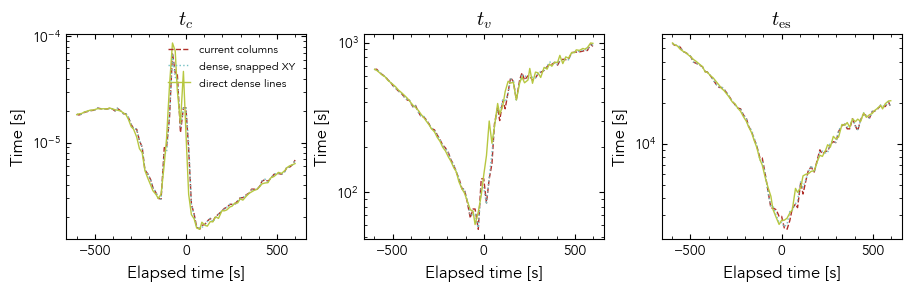

In [6]:
legacy = integrate_columns(grid_xy, z_legacy, "left")
exact_legacy = integrate_columns(exact_xy, z_legacy, "left")
dense_snapped = integrate_columns(grid_xy, z_reference)
reference = integrate_columns(exact_xy, z_reference)
complete_edges = np.concatenate([z_legacy, Z.reshape(1)])
completed_left = integrate_columns(grid_xy, complete_edges, "left")
rows = []
for label, result, baseline in [
    ("all effects: current / direct dense", legacy, reference),
    ("XY only: same legacy Z nodes", legacy, exact_legacy),
    ("XY only: same dense Z nodes", dense_snapped, reference),
    ("vertical only: same snapped XY", legacy, dense_snapped),
    ("restore omitted +Z interval", completed_left, legacy),
]:
    rows.extend(comparison_rows(label, result, baseline))
table = pd.DataFrame(rows)
display(table.round(3))
SUMMARIES[RUN]["baseline"] = table

fig, axes = plt.subplots(1, 3, figsize=(9, 2.8), sharex=True, layout="constrained")
for ax, name, label in zip(axes, TIME_FIELDS, TIME_LABELS):
    for result, legend, style in [
        (legacy, "current columns", "--"),
        (dense_snapped, "dense, snapped XY", ":"),
        (reference, "direct dense lines", "-"),
    ]:
        ax.semilogy(times, result[name], style, label=legend)
    ax.set_title(label)
    ax.set_xlabel("Elapsed time [s]")
    ax.set_ylabel("Time [s]")
axes[0].legend(fontsize=8)
plt.show()
plt.close(fig)

### XY and Z resolution separately

Nxy=128: dx=dy=1.5625 code_length; maximum XY offset=1.0834096810230416 code_length
Nxy=256: dx=dy=0.78125 code_length; maximum XY offset=0.5048505638937545 code_length


Nxy=512: dx=dy=0.390625 code_length; maximum XY offset=0.2553352777672267 code_length
Nxy=1024: dx=dy=0.1953125 code_length; maximum XY offset=0.12833700005398424 code_length


,comparison,quantity,median %,p90 %,max %
0,Nxy=128,tc,4.167,27.077,107.554
1,Nxy=128,tv,3.652,17.172,59.352
2,Nxy=128,tes,4.483,12.116,22.821
3,Nxy=256,tc,2.833,26.039,210.599
4,Nxy=256,tv,2.850,13.613,57.851
5,Nxy=256,tes,3.224,10.853,22.821
6,Nxy=512,tc,1.642,14.365,34.421
7,Nxy=512,tv,1.327,11.720,44.059
8,Nxy=512,tes,1.857,7.849,18.840
9,Nxy=1024,tc,0.623,7.153,78.632


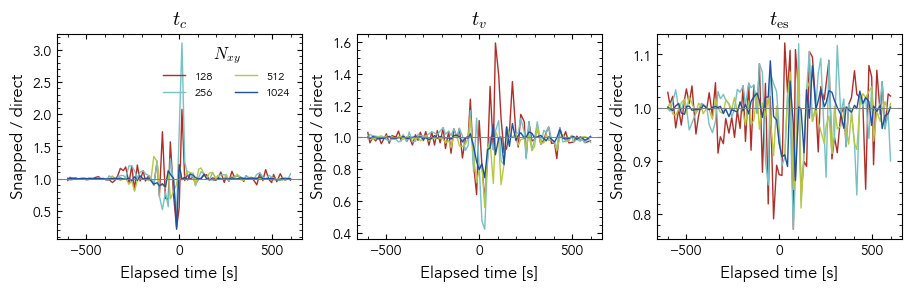

In [7]:
# Fixed dense Z quadrature: only the XY snapping changes.
xy_results = {}
rows = []
for nxy in NXY_VALUES:
    xy = snapped_xy(exact_xy, nxy)
    xy_results[nxy] = integrate_columns(xy, z_reference)
    rows.extend(comparison_rows(f"Nxy={nxy}", xy_results[nxy], reference))
    offset = np.sqrt(np.sum((xy - exact_xy) ** 2, axis=1))
    print(f"Nxy={nxy}: dx=dy={2 * XY / nxy}; maximum XY offset={offset.max()}")
table = pd.DataFrame(rows)
display(table.round(3))
SUMMARIES[RUN]["xy"] = table
fig, axes = plt.subplots(1, 3, figsize=(9, 2.8), sharex=True, layout="constrained")
for ax, name, label in zip(axes, TIME_FIELDS, TIME_LABELS):
    for nxy, result in xy_results.items():
        ax.plot(times, result[name] / reference[name], label=str(nxy))
    ax.axhline(1, color="0.5", lw=0.7)
    ax.set_title(label)
    ax.set_xlabel("Elapsed time [s]")
    ax.set_ylabel("Snapped / direct")
axes[0].legend(title=r"$N_{xy}$", fontsize=8, ncol=2)
plt.show()
plt.close(fig)
del xy_results

,comparison,quantity,median %,p90 %,max %,intervals,dz_min [Rsun],dz_max [Rsun]
0,left,tc,0.8938,5.2110,25.7357,256,0.2013,9.7485
1,left,tv,1.3497,14.1162,56.4089,256,0.2013,9.7485
2,left,tes,1.5907,11.2105,63.3087,256,0.2013,9.7485
3,midpoint,tc,0.7348,4.4050,25.0210,256,0.2013,9.7485
4,midpoint,tv,1.0699,10.3903,199.2128,256,0.2013,9.7485
5,midpoint,tes,1.2950,10.2096,48.4285,256,0.2013,9.7485
6,left,tc,0.5718,2.1197,13.8366,512,0.1006,4.9180
7,left,tv,0.6891,7.4668,29.5292,512,0.1006,4.9180
8,left,tes,0.7368,4.8157,28.2801,512,0.1006,4.9180
9,midpoint,tc,0.5325,1.9906,5.2709,512,0.1006,4.9180


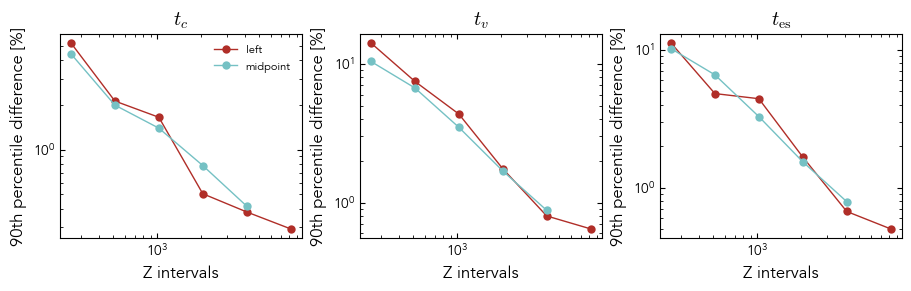

,comparison,quantity,median %,p90 %,max %
0,16384 / 8192 midpoint,tc,0.0376,0.2574,1.3988
1,16384 / 8192 midpoint,tv,0.0819,0.5461,2.6633
2,16384 / 8192 midpoint,tes,0.0643,0.5053,1.2363
3,16384 / 8192 midpoint,H,0.0300,0.1281,0.8329
4,16384 / 8192 midpoint,tau,0.0651,0.5837,1.0532


,comparison,quantity,median %,p90 %,max %
0,"NZ=256, dz0=0.1",tc,0.589,2.065,13.702
1,"NZ=256, dz0=0.1",tv,1.020,7.316,29.436
2,"NZ=256, dz0=0.1",tes,1.357,5.019,27.879
3,"NZ=512, dz0=0.1",tc,0.572,2.120,13.837
4,"NZ=512, dz0=0.1",tv,0.691,7.462,29.516
5,"NZ=512, dz0=0.1",tes,0.738,4.821,28.291
6,"NZ=1024, dz0=0.1",tc,0.540,2.142,13.861
7,"NZ=1024, dz0=0.1",tv,0.738,7.586,29.578
8,"NZ=1024, dz0=0.1",tes,0.736,4.778,28.345


In [8]:
# Preserve the sinh shape, refine its transformed-coordinate spacing.
# The symmetric bounds are complete for both quadrature rules.
rows = []
for nz in NZ_INTERVALS:
    edges = _grid_axis(-Z, Z, nz + 1, "sinh", sinh_scale, endpoint=True)
    for rule in ["left", "midpoint"]:
        result = integrate_columns(exact_xy, edges, rule)
        for row in comparison_rows(rule, result, reference):
            row["intervals"] = nz
            row["dz_min [Rsun]"] = np.diff(edges).min().to_value("Rsun")
            row["dz_max [Rsun]"] = np.diff(edges).max().to_value("Rsun")
            rows.append(row)
table = pd.DataFrame(rows)
display(table.round(4))
SUMMARIES[RUN]["z_resolution"] = table
fig, axes = plt.subplots(1, 3, figsize=(9, 2.8), sharex=True, layout="constrained")
for ax, name, label in zip(axes, TIME_FIELDS, TIME_LABELS):
    for rule in ["left", "midpoint"]:
        subset = table[(table["quantity"] == name) & (table["comparison"] == rule)]
        ax.loglog(
            subset["intervals"], subset["p90 %"].replace(0, np.nan), "o-", label=rule
        )
    ax.set_title(label)
    ax.set_xlabel("Z intervals")
    ax.set_ylabel("90th percentile difference [%]")
axes[0].legend(fontsize=8)
plt.show()
plt.close(fig)

# An independent doubling checks the chosen dense reference itself.
finer_edges = _grid_axis(-Z, Z, 2 * N_REFERENCE + 1, "sinh", sinh_scale, endpoint=True)
finer = integrate_columns(exact_xy, finer_edges)
fine_table = pd.DataFrame(
    comparison_rows(
        "16384 / 8192 midpoint", finer, reference, TIME_FIELDS + ["H", "tau"]
    )
)
display(fine_table.round(4))
SUMMARIES[RUN]["reference_check"] = fine_table

# This is the literal NZ-only change at fixed 0.1 midplane spacing.
fixed_spacing_rows = []
for nz in [256, 512, 1024]:
    edges = _grid_axis(
        -Z, Z, nz, "sinh", None, endpoint=False, central_spacing=DZ_DEFAULT
    )
    result = integrate_columns(exact_xy, edges, "left")
    fixed_spacing_rows.extend(comparison_rows(f"NZ={nz}, dz0=0.1", result, reference))
display(pd.DataFrame(fixed_spacing_rows).round(3))
SUMMARIES[RUN]["fixed_spacing"] = pd.DataFrame(fixed_spacing_rows)
del finer, finer_edges

### Adaptive library line integrals

cell_fraction: 0.25 step counts min/median/max: 153 205.0 348


cell_fraction: 0.125 step counts min/median/max: 302 407.5 693


cell_fraction: 0.0625 step counts min/median/max: 600 810.5 1382


,comparison,quantity,median %,p90 %,max %
0,f=0.25,tau,0.6871,2.9512,7.3607
1,f=0.25,tes,0.6871,2.9512,7.3607
2,f=0.125,tau,0.3969,1.8808,3.3708
3,f=0.125,tes,0.3969,1.8808,3.3708
4,f=0.0625,tau,0.1946,1.0774,2.2799
5,f=0.0625,tes,0.1946,1.0774,2.2799


,comparison,quantity,median %,p90 %,max %
0,f=0.25 / 0.125,tau,0.6089,3.6921,6.8965
1,f=0.125 / 0.0625,tau,0.2792,1.6663,3.5478


,comparison,quantity,median %,p90 %,max %
0,adaptive library / dense midpoint,tc,0.111,0.4528,3.3929


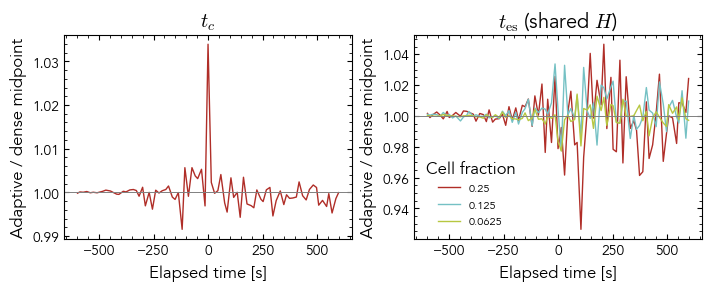

In [9]:
# Start at z=0 and integrate both signs to the same +/-10 rp bounds.
midplane = u.unyt_array(np.zeros((len(exact_xy), 3)), exact_xy.units)
midplane[:, :2] = exact_xy
p0 = np.concatenate([midplane, midplane])
p1 = p0.copy()
p1[: len(exact_xy), 2] = Z
p1[len(exact_xy) :, 2] = -Z
adaptive = {}
rows = []
for fraction in CELL_FRACTIONS:
    rays = richio.analysis.integrate_optical_depth(
        fields["position"],
        alpha,
        fields["volume"],
        p0,
        p1,
        cell_fraction=fraction,
        max_delta_tau=None,
        tree=tree,
        workers=1,
    )
    upper, lower = np.split(rays["tau"], 2)
    tau = 0.5 * (upper + lower)
    adaptive[fraction] = {"tau": tau, "tes": (reference["H"] * tau / u.c).to("s")}
    rows.extend(
        comparison_rows(f"f={fraction}", adaptive[fraction], reference, ["tau", "tes"])
    )
    print(
        "cell_fraction:",
        fraction,
        "step counts min/median/max:",
        rays["steps"].min(),
        np.median(rays["steps"]),
        rays["steps"].max(),
    )
table = pd.DataFrame(rows)
display(table.round(4))
SUMMARIES[RUN]["adaptive"] = table
rows = []
for previous, current in zip(CELL_FRACTIONS[:-1], CELL_FRACTIONS[1:]):
    rows.extend(
        comparison_rows(
            f"f={previous} / {current}", adaptive[previous], adaptive[current], ["tau"]
        )
    )
display(pd.DataFrame(rows).round(4))
SUMMARIES[RUN]["adaptive_refinement"] = pd.DataFrame(rows)

# Reuse the same library quadrature for the two positive t_c integrands.
# Normalization gives inverse-length inputs; the physical integrals are restored.
library_integrals = {}
for name, field in [("energy", internal), ("emission", emissivity)]:
    scale = field.max()
    rays = richio.analysis.integrate_optical_depth(
        fields["position"],
        field / (scale * RP),
        fields["volume"],
        p0,
        p1,
        cell_fraction=CELL_FRACTIONS[-1],
        max_delta_tau=None,
        tree=tree,
        workers=1,
    )
    upper, lower = np.split(rays["tau"], 2)
    library_integrals[name] = (upper + lower) * scale * RP
library_tc = {
    "tc": (library_integrals["energy"] / library_integrals["emission"]).to("s")
}
tc_table = pd.DataFrame(
    comparison_rows("adaptive library / dense midpoint", library_tc, reference, ["tc"])
)
display(tc_table.round(4))
SUMMARIES[RUN]["adaptive_tc"] = tc_table

fig, axes = plt.subplots(1, 2, figsize=(7, 2.8), sharex=True, layout="constrained")
axes[0].plot(times, library_tc["tc"] / reference["tc"])
axes[0].set_title(r"$t_c$")
for fraction, result in adaptive.items():
    axes[1].plot(times, result["tes"] / reference["tes"], label=str(fraction))
axes[1].set_title(r"$t_{\rm es}$ (shared $H$)")
axes[1].legend(title="Cell fraction", fontsize=8)
for ax in axes:
    ax.axhline(1, color="0.5", lw=0.7)
    ax.set_xlabel("Elapsed time [s]")
    ax.set_ylabel("Adaptive / dense midpoint")
plt.show()
plt.close(fig)
del rays, library_integrals, field

### Vertical limit with unchanged interior samples

Z/rp=2: 5326 intervals; min/max dz=0.0062496662951655605 code_length, 0.06187610867677762 code_length
Z/rp=5: 6958 intervals; min/max dz=0.0062496662951655605 code_length, 0.1539294893816816 code_length
Z/rp=10: 8196 intervals; min/max dz=0.0062496662951655605 code_length, 0.30797026507497094 code_length


Z/rp=20: 9434 intervals; min/max dz=0.0062496662951655605 code_length, 0.6156158561667553 code_length


Z/rp=40: 10672 intervals; min/max dz=0.0062496662951655605 code_length, 1.2306539387236626 code_length


,comparison,quantity,median %,p90 %,max %
0,Z=2 / 10 rp,tc,0.0001,0.0009,0.0014
1,Z=2 / 10 rp,tv,0.3940,0.6535,0.9159
2,Z=2 / 10 rp,tes,0.6173,0.7738,0.9617
3,Z=2 / 10 rp,H,0.6000,0.7606,0.9580
4,Z=2 / 10 rp,tau,0.0037,0.0194,0.0309
5,Z=2 / 10 rp,sigma,0.0008,0.0055,0.0090
6,Z=2 / 10 rp,tes/tv,0.0514,0.2595,0.3486
7,Z=5 / 10 rp,tc,0.0000,0.0002,0.0002
8,Z=5 / 10 rp,tv,0.1572,0.3861,0.5906
9,Z=5 / 10 rp,tes,0.2096,0.4326,0.6134


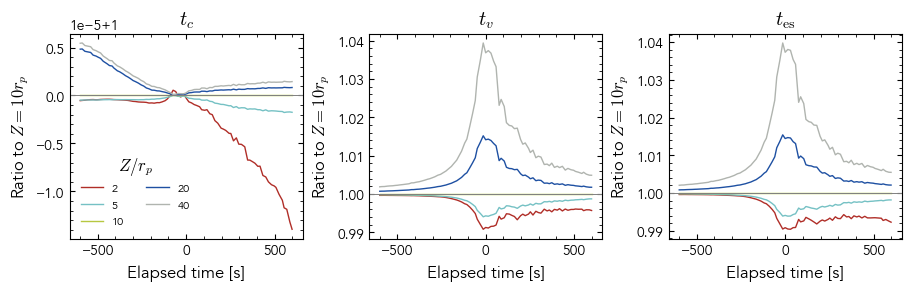

,comparison,quantity,median %,p90 %,max %
0,40 rp: halve every interval,tc,0.0376,0.2574,1.3988
1,40 rp: halve every interval,tv,0.0814,0.5297,2.6274
2,40 rp: halve every interval,tes,0.0638,0.4972,1.1951
3,40 rp: halve every interval,H,0.0297,0.1310,0.7885
4,40 rp: halve every interval,tau,0.0651,0.5837,1.0531


,comparison,quantity,median %,p90 %,max %
0,40 / 20 rp,tc,0.0000,0.0001,0.0001
1,40 / 20 rp,tv,0.4392,1.5203,2.3830
2,40 / 20 rp,tes,0.4653,1.5571,2.4011
3,40 / 20 rp,H,0.4610,1.5531,2.3974
4,40 / 20 rp,tau,0.0036,0.0044,0.0046
5,40 / 20 rp,sigma,0.0004,0.0005,0.0005
6,40 / 20 rp,tes/tv,0.0214,0.0362,0.0465


,Z/rp,median tc [s],median tv [s],median tes [s],"median max(tc,tes)/tv","sample fraction max(tc,tes)<tv"
0,2,5.2489e-06,483.14,14617,21.151,0
1,5,5.2489e-06,483.2,14623,21.201,0
2,10,5.249e-06,483.31,14636,21.214,0
3,20,5.249e-06,483.79,14679,21.22,0
4,40,5.249e-06,484.51,14744,21.226,0


In [10]:
# One fine sinh lattice, with every cutoff inserted before midpoint sampling.
# Each truncated integral therefore uses exactly the same interior intervals.
du = 2 * np.arcsinh(Z / sinh_scale) / N_REFERENCE
largest_z = max(Z_LIMITS_RP) * RP
kmax = int(np.ceil(np.arcsinh(largest_z / sinh_scale) / du))
lattice = sinh_scale * np.sinh(np.arange(-kmax, kmax + 1) * du)
limits = np.array(Z_LIMITS_RP) * RP
# Replace nearly coincident lattice knots by the exact cutoff values.
for boundary in limits:
    lattice = lattice[~np.isclose(np.abs(lattice / boundary), 1, rtol=1e-12, atol=0)]
common_edges = np.unique(
    np.concatenate([lattice[np.abs(lattice) < largest_z], limits, -limits])
)
assert common_edges[0] >= snap.box[2] and common_edges[-1] <= snap.box[5]
cutoff = {}
for limit in Z_LIMITS_RP:
    edges = common_edges[np.abs(common_edges) <= limit * RP]
    cutoff[limit] = integrate_columns(exact_xy, edges)
    print(
        f"Z/rp={limit}: {len(edges) - 1} intervals; min/max dz={np.diff(edges).min()}, {np.diff(edges).max()}"
    )
rows = []
for limit in Z_LIMITS_RP:
    rows.extend(
        comparison_rows(
            f"Z={limit} / 10 rp",
            cutoff[limit],
            cutoff[10],
            TIME_FIELDS + ["H", "tau", "sigma", "tes/tv"],
        )
    )
table = pd.DataFrame(rows)
display(table.round(4))
SUMMARIES[RUN]["cutoff"] = table
fig, axes = plt.subplots(1, 3, figsize=(9, 2.8), sharex=True, layout="constrained")
for ax, name, label in zip(axes, TIME_FIELDS, TIME_LABELS):
    for limit, result in cutoff.items():
        ax.plot(times, result[name] / cutoff[10][name], label=str(limit))
    ax.axhline(1, color="0.5", lw=0.7)
    ax.set_title(label)
    ax.set_xlabel("Elapsed time [s]")
    ax.set_ylabel(r"Ratio to $Z=10r_p$")
axes[0].legend(title=r"$Z/r_p$", fontsize=8, ncol=2)
plt.show()
plt.close(fig)

# Tail sensitivity is physical to these definitions only if quadrature is stable.
refined_edges = np.sort(
    np.concatenate([common_edges, 0.5 * (common_edges[1:] + common_edges[:-1])])
)
tail_finer = integrate_columns(exact_xy, refined_edges)
tail_check = pd.DataFrame(
    comparison_rows(
        "40 rp: halve every interval",
        tail_finer,
        cutoff[40],
        TIME_FIELDS + ["H", "tau"],
    )
)
display(tail_check.round(4))
SUMMARIES[RUN]["tail_check"] = tail_check
tail_rows = comparison_rows(
    "40 / 20 rp", cutoff[40], cutoff[20], TIME_FIELDS + ["H", "tau", "sigma", "tes/tv"]
)
display(pd.DataFrame(tail_rows).round(4))
SUMMARIES[RUN]["outer_tail"] = pd.DataFrame(tail_rows)

# Interpret changes using the moments, and the same effective-cooling proxy.
rows = []
for limit in Z_LIMITS_RP:
    result = cutoff[limit]
    effective = np.maximum(result["tc"], result["tes"]) / result["tv"]
    rows.append(
        {
            "Z/rp": limit,
            "median tc [s]": np.median(result["tc"].to_value("s")),
            "median tv [s]": np.median(result["tv"].to_value("s")),
            "median tes [s]": np.median(result["tes"].to_value("s")),
            "median max(tc,tes)/tv": np.median(effective.to_value("dimensionless")),
            "sample fraction max(tc,tes)<tv": np.mean(effective < 1),
        }
    )
with pd.option_context("display.float_format", "{:.5g}".format):
    display(pd.DataFrame(rows))
SUMMARIES[RUN]["physical"] = pd.DataFrame(rows)
# Free all full-snapshot arrays before the next run; retain only small tables.
snap.f.close()
del snap, streamline
fields = tree = internal = emissivity = alpha = None
del legacy, exact_legacy, dense_snapped, reference, completed_left
del adaptive, cutoff, tail_finer, result, baseline

## 1e4: snapshot 151

In [11]:
RUN = "1e4"
SNAPSHOT = 151
SNAPSHOT_PATH = "/data1/projects/pi-rossiem/TDE_data/NewSnellius/R0.47M0.5BH10000beta1S60ComptonHiRes/snap_full_151.h5"
XY = 30 * richio.units.lscale
RSTAR = 0.47 * richio.units.lscale
MSTAR = 0.5 * richio.units.mscale
MBH = 1e4 * richio.units.mscale
RP = RSTAR * (MBH / MSTAR) ** (1 / 3)
t_fb = dev.TDEBasics(MBH, MSTAR, RSTAR).t_fb
snap = richio.load(SNAPSHOT_PATH)
print(SNAPSHOT_PATH)
print("Time:", snap.time.to("day"), "t/tfb:", (snap.time / t_fb).to("dimensionless"))
print("rp:", RP.to("Rsun"), "XY bounds:", -XY, XY)

# Only the fields needed here; all coordinates follow the source notebook.
fields = {
    "position": np.column_stack([snap.X, snap.Y, snap.Z]),
    "velocity": np.column_stack([snap.vx, snap.vy, snap.vz]),
    "density": snap.rho,
    "volume": snap.volume,
}
tree = cKDTree(fields["position"].to_value("code_length"))
seed = cooling.get_max_density_cell(fields, RP.to_value("code_length"))
streamline = cooling.get_streamline(fields, seed, tree)
requested_time = np.linspace(-600, 600, N_TIME_SAMPLES) * u.s
# unyt retains units on argmin indices; indexing itself requires plain integers.
selected = np.unique(
    np.r_[
        np.asarray(np.abs(streamline["time"][:, None] - requested_time).argmin(axis=0)),
        np.flatnonzero(streamline["indices"] == seed),
    ]
)
times = streamline["time"][selected]
exact_xy = streamline["positions"][selected, :2]
assert np.all(np.abs(exact_xy) < XY)
temperature = snap.T
internal = fields["density"] * snap.sie
alpha = richio.opacity.rosseland_alpha(temperature, fields["density"])
emissivity = (
    richio.opacity.planck_alpha(temperature, fields["density"])
    * A_RAD
    * temperature**4
    * u.c
)
del temperature
Z = Z_DEFAULT_RP * RP
z_legacy = _grid_axis(
    -Z, Z, NZ_DEFAULT, "sinh", None, endpoint=False, central_spacing=DZ_DEFAULT
)
sinh_scale = _sinh_scale_from_spacing(-Z, Z, NZ_DEFAULT, DZ_DEFAULT, endpoint=False)
z_reference = _grid_axis(-Z, Z, N_REFERENCE + 1, "sinh", sinh_scale, endpoint=True)
grid_xy = snapped_xy(exact_xy, NXY_DEFAULT)
print("Native cells:", len(fields["density"]), "selected rays:", len(selected))
print(
    "Seed:",
    seed,
    "position:",
    fields["position"][seed],
    "density:",
    fields["density"][seed],
)
print(
    "Trace: midpoint dx/dt=v, 961 output times, 1.25 s spacing; max spatial step",
    cooling.MAX_LSTEP,
)
print(
    "Legacy grid:",
    (NXY_DEFAULT, NXY_DEFAULT, NZ_DEFAULT),
    "XY spacing:",
    2 * XY / NXY_DEFAULT,
)
print(
    "Legacy actual Z/rp:",
    z_legacy[[0, -1]] / RP,
    "min/max dz:",
    np.diff(z_legacy).min(),
    np.diff(z_legacy).max(),
)
print("Reference: exact XY;", N_REFERENCE, "midpoint intervals; Z/rp=+/-", Z_DEFAULT_RP)
print(
    "Reference min/max dz:",
    np.diff(z_reference).min(),
    np.diff(z_reference).max(),
    "sinh scale:",
    sinh_scale,
)
SUMMARIES[RUN] = {"snapshot": SNAPSHOT, "rays": len(selected)}

/data1/projects/pi-rossiem/TDE_data/NewSnellius/R0.47M0.5BH10000beta1S60ComptonHiRes/snap_full_151.h5
Time: [5.77629162] day t/tfb: [2.17477753] dimensionless
rp: 12.840307436963515 Rsun XY bounds: -30 code_length 30 code_length


Native cells: 70481016 selected rays: 81
Seed: 45467225 position: [ 1.22281026e+01 -2.90382434e+00 -9.63939573e-03] code_length density: 4.535071998682503e-05 code_mass/code_length**3
Trace: midpoint dx/dt=v, 961 output times, 1.25 s spacing; max spatial step 0.04967857218616965 code_length
Legacy grid: (256, 256, 512) XY spacing: 0.234375 code_length
Legacy actual Z/rp: [-10.           9.86115227] dimensionless min/max dz: 0.0999999999999999 code_length 1.7713864604359486 code_length
Reference: exact XY; 8192 midpoint intervals; Z/rp=+/- 10
Reference min/max dz: 0.006249797802526553 code_length 0.1114364301783155 code_length sinh scale: 7.163208545059019 code_length


### Current columns versus direct lines

,comparison,quantity,median %,p90 %,max %
0,all effects: current / direct dense,tc,4.083,12.139,25.963
1,all effects: current / direct dense,tv,3.418,9.194,33.515
2,all effects: current / direct dense,tes,4.449,11.951,17.553
3,XY only: same legacy Z nodes,tc,3.685,12.910,25.414
4,XY only: same legacy Z nodes,tv,4.219,12.901,38.624
5,XY only: same legacy Z nodes,tes,4.229,11.981,17.089
6,XY only: same dense Z nodes,tc,3.561,11.402,25.327
7,XY only: same dense Z nodes,tv,1.990,6.017,20.431
8,XY only: same dense Z nodes,tes,2.159,10.471,18.436
9,vertical only: same snapped XY,tc,1.944,5.489,14.823


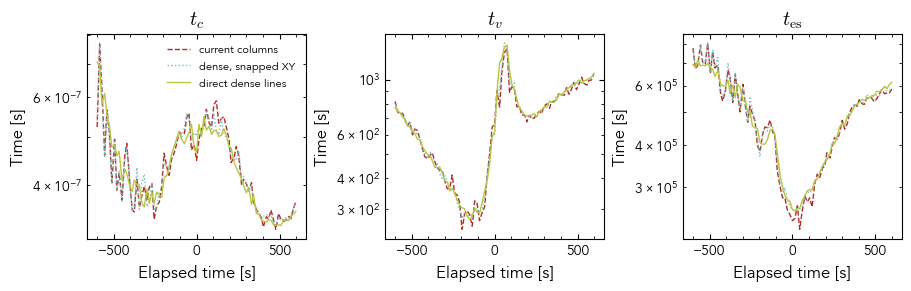

In [12]:
legacy = integrate_columns(grid_xy, z_legacy, "left")
exact_legacy = integrate_columns(exact_xy, z_legacy, "left")
dense_snapped = integrate_columns(grid_xy, z_reference)
reference = integrate_columns(exact_xy, z_reference)
complete_edges = np.concatenate([z_legacy, Z.reshape(1)])
completed_left = integrate_columns(grid_xy, complete_edges, "left")
rows = []
for label, result, baseline in [
    ("all effects: current / direct dense", legacy, reference),
    ("XY only: same legacy Z nodes", legacy, exact_legacy),
    ("XY only: same dense Z nodes", dense_snapped, reference),
    ("vertical only: same snapped XY", legacy, dense_snapped),
    ("restore omitted +Z interval", completed_left, legacy),
]:
    rows.extend(comparison_rows(label, result, baseline))
table = pd.DataFrame(rows)
display(table.round(3))
SUMMARIES[RUN]["baseline"] = table

fig, axes = plt.subplots(1, 3, figsize=(9, 2.8), sharex=True, layout="constrained")
for ax, name, label in zip(axes, TIME_FIELDS, TIME_LABELS):
    for result, legend, style in [
        (legacy, "current columns", "--"),
        (dense_snapped, "dense, snapped XY", ":"),
        (reference, "direct dense lines", "-"),
    ]:
        ax.semilogy(times, result[name], style, label=legend)
    ax.set_title(label)
    ax.set_xlabel("Elapsed time [s]")
    ax.set_ylabel("Time [s]")
axes[0].legend(fontsize=8)
plt.show()
plt.close(fig)

### XY and Z resolution separately

Nxy=128: dx=dy=0.46875 code_length; maximum XY offset=0.3025216778523753 code_length
Nxy=256: dx=dy=0.234375 code_length; maximum XY offset=0.16005323154293943 code_length
Nxy=512: dx=dy=0.1171875 code_length; maximum XY offset=0.07329109344531867 code_length


Nxy=1024: dx=dy=0.05859375 code_length; maximum XY offset=0.035140075784313905 code_length


,comparison,quantity,median %,p90 %,max %
0,Nxy=128,tc,8.107,20.891,28.060
1,Nxy=128,tv,3.566,8.913,13.150
2,Nxy=128,tes,4.973,18.521,31.984
3,Nxy=256,tc,3.561,11.402,25.327
4,Nxy=256,tv,1.990,6.017,20.431
5,Nxy=256,tes,2.159,10.471,18.436
6,Nxy=512,tc,1.984,6.437,14.324
7,Nxy=512,tv,1.044,5.032,12.555
8,Nxy=512,tes,1.328,4.414,9.575
9,Nxy=1024,tc,0.672,2.512,4.709


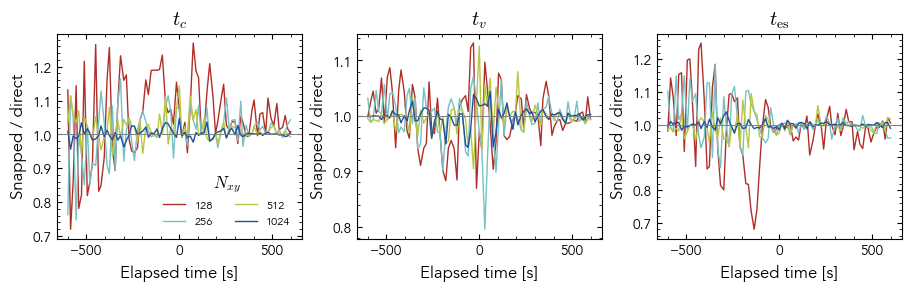

In [13]:
# Fixed dense Z quadrature: only the XY snapping changes.
xy_results = {}
rows = []
for nxy in NXY_VALUES:
    xy = snapped_xy(exact_xy, nxy)
    xy_results[nxy] = integrate_columns(xy, z_reference)
    rows.extend(comparison_rows(f"Nxy={nxy}", xy_results[nxy], reference))
    offset = np.sqrt(np.sum((xy - exact_xy) ** 2, axis=1))
    print(f"Nxy={nxy}: dx=dy={2 * XY / nxy}; maximum XY offset={offset.max()}")
table = pd.DataFrame(rows)
display(table.round(3))
SUMMARIES[RUN]["xy"] = table
fig, axes = plt.subplots(1, 3, figsize=(9, 2.8), sharex=True, layout="constrained")
for ax, name, label in zip(axes, TIME_FIELDS, TIME_LABELS):
    for nxy, result in xy_results.items():
        ax.plot(times, result[name] / reference[name], label=str(nxy))
    ax.axhline(1, color="0.5", lw=0.7)
    ax.set_title(label)
    ax.set_xlabel("Elapsed time [s]")
    ax.set_ylabel("Snapped / direct")
axes[0].legend(title=r"$N_{xy}$", fontsize=8, ncol=2)
plt.show()
plt.close(fig)
del xy_results

,comparison,quantity,median %,p90 %,max %,intervals,dz_min [Rsun],dz_max [Rsun]
0,left,tc,3.0638,12.9732,23.4182,256,0.2013,3.5410
1,left,tv,4.2441,15.3445,31.6036,256,0.2013,3.5410
2,left,tes,3.8457,18.4610,22.1550,256,0.2013,3.5410
3,midpoint,tc,5.4486,42.1530,152.9898,256,0.2013,3.5410
4,midpoint,tv,3.8702,17.4319,39.2924,256,0.2013,3.5410
5,midpoint,tes,3.1357,9.2365,23.7451,256,0.2013,3.5410
6,left,tc,1.8169,5.1251,10.8814,512,0.1006,1.7828
7,left,tv,1.8124,7.3985,10.7092,512,0.1006,1.7828
8,left,tes,1.7374,6.2037,10.4037,512,0.1006,1.7828
9,midpoint,tc,1.5780,7.2580,31.6172,512,0.1006,1.7828


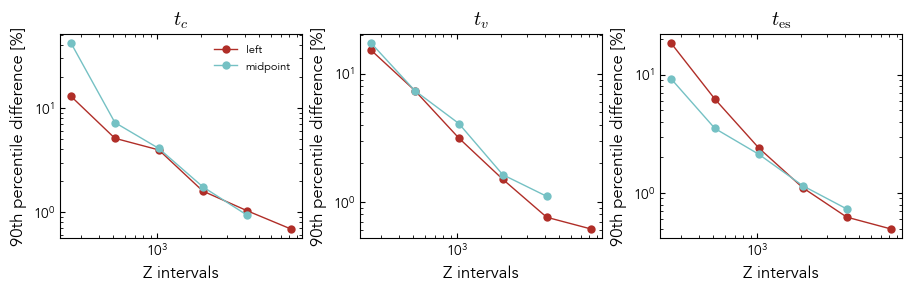

,comparison,quantity,median %,p90 %,max %
0,16384 / 8192 midpoint,tc,0.1404,0.4197,0.8666
1,16384 / 8192 midpoint,tv,0.1627,0.3955,1.1839
2,16384 / 8192 midpoint,tes,0.1227,0.4249,0.6482
3,16384 / 8192 midpoint,H,0.0854,0.4372,0.9557
4,16384 / 8192 midpoint,tau,0.2029,0.8095,1.4389


,comparison,quantity,median %,p90 %,max %
0,"NZ=256, dz0=0.1",tc,1.797,5.322,11.016
1,"NZ=256, dz0=0.1",tv,1.742,7.239,11.350
2,"NZ=256, dz0=0.1",tes,1.405,5.302,10.907
3,"NZ=512, dz0=0.1",tc,1.817,5.125,10.881
4,"NZ=512, dz0=0.1",tv,1.808,7.504,10.778
5,"NZ=512, dz0=0.1",tes,1.742,6.137,10.484
6,"NZ=1024, dz0=0.1",tc,1.915,5.255,10.893
7,"NZ=1024, dz0=0.1",tv,2.138,7.297,10.934
8,"NZ=1024, dz0=0.1",tes,1.518,5.997,11.384


In [14]:
# Preserve the sinh shape, refine its transformed-coordinate spacing.
# The symmetric bounds are complete for both quadrature rules.
rows = []
for nz in NZ_INTERVALS:
    edges = _grid_axis(-Z, Z, nz + 1, "sinh", sinh_scale, endpoint=True)
    for rule in ["left", "midpoint"]:
        result = integrate_columns(exact_xy, edges, rule)
        for row in comparison_rows(rule, result, reference):
            row["intervals"] = nz
            row["dz_min [Rsun]"] = np.diff(edges).min().to_value("Rsun")
            row["dz_max [Rsun]"] = np.diff(edges).max().to_value("Rsun")
            rows.append(row)
table = pd.DataFrame(rows)
display(table.round(4))
SUMMARIES[RUN]["z_resolution"] = table
fig, axes = plt.subplots(1, 3, figsize=(9, 2.8), sharex=True, layout="constrained")
for ax, name, label in zip(axes, TIME_FIELDS, TIME_LABELS):
    for rule in ["left", "midpoint"]:
        subset = table[(table["quantity"] == name) & (table["comparison"] == rule)]
        ax.loglog(
            subset["intervals"], subset["p90 %"].replace(0, np.nan), "o-", label=rule
        )
    ax.set_title(label)
    ax.set_xlabel("Z intervals")
    ax.set_ylabel("90th percentile difference [%]")
axes[0].legend(fontsize=8)
plt.show()
plt.close(fig)

# An independent doubling checks the chosen dense reference itself.
finer_edges = _grid_axis(-Z, Z, 2 * N_REFERENCE + 1, "sinh", sinh_scale, endpoint=True)
finer = integrate_columns(exact_xy, finer_edges)
fine_table = pd.DataFrame(
    comparison_rows(
        "16384 / 8192 midpoint", finer, reference, TIME_FIELDS + ["H", "tau"]
    )
)
display(fine_table.round(4))
SUMMARIES[RUN]["reference_check"] = fine_table

# This is the literal NZ-only change at fixed 0.1 midplane spacing.
fixed_spacing_rows = []
for nz in [256, 512, 1024]:
    edges = _grid_axis(
        -Z, Z, nz, "sinh", None, endpoint=False, central_spacing=DZ_DEFAULT
    )
    result = integrate_columns(exact_xy, edges, "left")
    fixed_spacing_rows.extend(comparison_rows(f"NZ={nz}, dz0=0.1", result, reference))
display(pd.DataFrame(fixed_spacing_rows).round(3))
SUMMARIES[RUN]["fixed_spacing"] = pd.DataFrame(fixed_spacing_rows)
del finer, finer_edges

### Adaptive library line integrals

cell_fraction: 0.25 step counts min/median/max: 627 671.5 708


cell_fraction: 0.125 step counts min/median/max: 1248 1339.0 1412


cell_fraction: 0.0625 step counts min/median/max: 2493 2674.0 2818


,comparison,quantity,median %,p90 %,max %
0,f=0.25,tau,0.8326,2.2562,4.7019
1,f=0.25,tes,0.8326,2.2562,4.7019
2,f=0.125,tau,0.3698,1.3774,3.4942
3,f=0.125,tes,0.3698,1.3774,3.4942
4,f=0.0625,tau,0.3093,0.9302,1.5873
5,f=0.0625,tes,0.3093,0.9302,1.5873


,comparison,quantity,median %,p90 %,max %
0,f=0.25 / 0.125,tau,0.5577,1.7014,3.0013
1,f=0.125 / 0.0625,tau,0.3478,0.9741,2.1644


,comparison,quantity,median %,p90 %,max %
0,adaptive library / dense midpoint,tc,0.1565,0.5153,1.1594


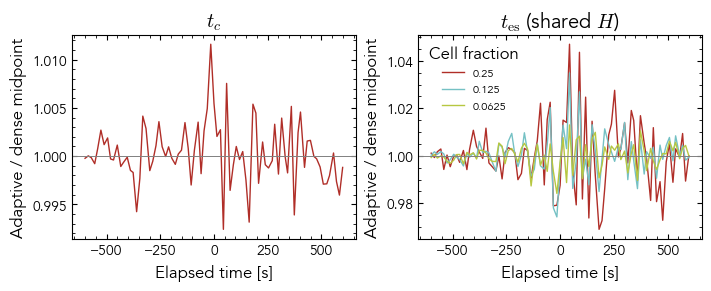

In [15]:
# Start at z=0 and integrate both signs to the same +/-10 rp bounds.
midplane = u.unyt_array(np.zeros((len(exact_xy), 3)), exact_xy.units)
midplane[:, :2] = exact_xy
p0 = np.concatenate([midplane, midplane])
p1 = p0.copy()
p1[: len(exact_xy), 2] = Z
p1[len(exact_xy) :, 2] = -Z
adaptive = {}
rows = []
for fraction in CELL_FRACTIONS:
    rays = richio.analysis.integrate_optical_depth(
        fields["position"],
        alpha,
        fields["volume"],
        p0,
        p1,
        cell_fraction=fraction,
        max_delta_tau=None,
        tree=tree,
        workers=1,
    )
    upper, lower = np.split(rays["tau"], 2)
    tau = 0.5 * (upper + lower)
    adaptive[fraction] = {"tau": tau, "tes": (reference["H"] * tau / u.c).to("s")}
    rows.extend(
        comparison_rows(f"f={fraction}", adaptive[fraction], reference, ["tau", "tes"])
    )
    print(
        "cell_fraction:",
        fraction,
        "step counts min/median/max:",
        rays["steps"].min(),
        np.median(rays["steps"]),
        rays["steps"].max(),
    )
table = pd.DataFrame(rows)
display(table.round(4))
SUMMARIES[RUN]["adaptive"] = table
rows = []
for previous, current in zip(CELL_FRACTIONS[:-1], CELL_FRACTIONS[1:]):
    rows.extend(
        comparison_rows(
            f"f={previous} / {current}", adaptive[previous], adaptive[current], ["tau"]
        )
    )
display(pd.DataFrame(rows).round(4))
SUMMARIES[RUN]["adaptive_refinement"] = pd.DataFrame(rows)

# Reuse the same library quadrature for the two positive t_c integrands.
# Normalization gives inverse-length inputs; the physical integrals are restored.
library_integrals = {}
for name, field in [("energy", internal), ("emission", emissivity)]:
    scale = field.max()
    rays = richio.analysis.integrate_optical_depth(
        fields["position"],
        field / (scale * RP),
        fields["volume"],
        p0,
        p1,
        cell_fraction=CELL_FRACTIONS[-1],
        max_delta_tau=None,
        tree=tree,
        workers=1,
    )
    upper, lower = np.split(rays["tau"], 2)
    library_integrals[name] = (upper + lower) * scale * RP
library_tc = {
    "tc": (library_integrals["energy"] / library_integrals["emission"]).to("s")
}
tc_table = pd.DataFrame(
    comparison_rows("adaptive library / dense midpoint", library_tc, reference, ["tc"])
)
display(tc_table.round(4))
SUMMARIES[RUN]["adaptive_tc"] = tc_table

fig, axes = plt.subplots(1, 2, figsize=(7, 2.8), sharex=True, layout="constrained")
axes[0].plot(times, library_tc["tc"] / reference["tc"])
axes[0].set_title(r"$t_c$")
for fraction, result in adaptive.items():
    axes[1].plot(times, result["tes"] / reference["tes"], label=str(fraction))
axes[1].set_title(r"$t_{\rm es}$ (shared $H$)")
axes[1].legend(title="Cell fraction", fontsize=8)
for ax in axes:
    ax.axhline(1, color="0.5", lw=0.7)
    ax.set_xlabel("Elapsed time [s]")
    ax.set_ylabel("Adaptive / dense midpoint")
plt.show()
plt.close(fig)
del rays, library_integrals, field

### Vertical limit with unchanged interior samples

Z/rp=2: 4546 intervals; min/max dz=0.006249797802526971 code_length, 0.023105429974688008 code_length
Z/rp=5: 6612 intervals; min/max dz=0.006249797802526971 code_length, 0.055968573911606256 code_length
Z/rp=10: 8196 intervals; min/max dz=0.006249797802526971 code_length, 0.1114364301783155 code_length


Z/rp=20: 9784 intervals; min/max dz=0.006249797802526971 code_length, 0.22245960839671852 code_length
Z/rp=40: 11376 intervals; min/max dz=0.006249797802526971 code_length, 0.4450664527834647 code_length


,comparison,quantity,median %,p90 %,max %
0,Z=2 / 10 rp,tc,0.0504,0.0961,0.1889
1,Z=2 / 10 rp,tv,24.3081,35.0953,37.6447
2,Z=2 / 10 rp,tes,24.9907,36.4457,39.4923
3,Z=2 / 10 rp,H,24.8681,36.3147,39.3744
4,Z=2 / 10 rp,tau,0.1909,0.2261,0.2838
5,Z=2 / 10 rp,sigma,0.1912,0.2473,0.3193
6,Z=2 / 10 rp,tes/tv,0.8033,1.7702,3.1618
7,Z=5 / 10 rp,tc,0.0069,0.0117,0.0151
8,Z=5 / 10 rp,tv,9.8664,14.0346,16.1016
9,Z=5 / 10 rp,tes,10.1159,14.5564,16.7682


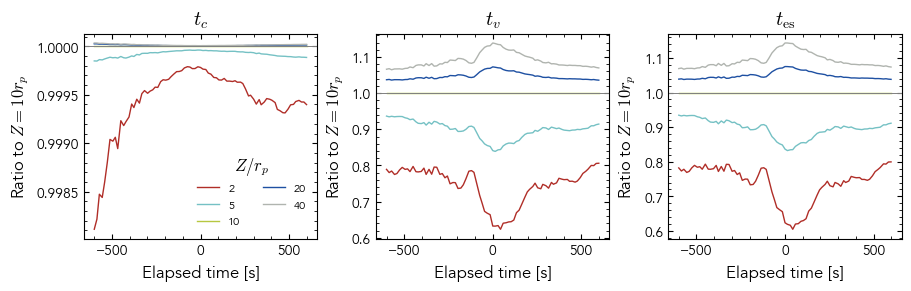

,comparison,quantity,median %,p90 %,max %
0,40 rp: halve every interval,tc,0.1404,0.4197,0.8667
1,40 rp: halve every interval,tv,0.1579,0.3736,1.1265
2,40 rp: halve every interval,tes,0.1126,0.3956,0.5695
3,40 rp: halve every interval,H,0.0840,0.4509,1.0078
4,40 rp: halve every interval,tau,0.2027,0.8086,1.4376


,comparison,quantity,median %,p90 %,max %
0,40 / 20 rp,tc,0.0004,0.0006,0.0009
1,40 / 20 rp,tv,3.7655,5.5430,6.1600
2,40 / 20 rp,tes,3.8773,5.7663,6.3386
3,40 / 20 rp,H,3.8171,5.7011,6.2726
4,40 / 20 rp,tau,0.0620,0.0669,0.0743
5,40 / 20 rp,sigma,0.0047,0.0056,0.0059
6,40 / 20 rp,tes/tv,0.1403,0.1765,0.2781


,Z/rp,median tc [s],median tv [s],median tes [s],"median max(tc,tes)/tv","sample fraction max(tc,tes)<tv"
0,2,4.2125e-07,523.29,3.7483e+05,609.25,0
1,5,4.2152e-07,642.44,4.5261e+05,612.66,0
2,10,4.2157e-07,717.13,5.0227e+05,614.86,0
3,20,4.2158e-07,754,5.2537e+05,615.95,0
4,40,4.2159e-07,786.44,5.4574e+05,616.83,0


In [16]:
# One fine sinh lattice, with every cutoff inserted before midpoint sampling.
# Each truncated integral therefore uses exactly the same interior intervals.
du = 2 * np.arcsinh(Z / sinh_scale) / N_REFERENCE
largest_z = max(Z_LIMITS_RP) * RP
kmax = int(np.ceil(np.arcsinh(largest_z / sinh_scale) / du))
lattice = sinh_scale * np.sinh(np.arange(-kmax, kmax + 1) * du)
limits = np.array(Z_LIMITS_RP) * RP
# Replace nearly coincident lattice knots by the exact cutoff values.
for boundary in limits:
    lattice = lattice[~np.isclose(np.abs(lattice / boundary), 1, rtol=1e-12, atol=0)]
common_edges = np.unique(
    np.concatenate([lattice[np.abs(lattice) < largest_z], limits, -limits])
)
assert common_edges[0] >= snap.box[2] and common_edges[-1] <= snap.box[5]
cutoff = {}
for limit in Z_LIMITS_RP:
    edges = common_edges[np.abs(common_edges) <= limit * RP]
    cutoff[limit] = integrate_columns(exact_xy, edges)
    print(
        f"Z/rp={limit}: {len(edges) - 1} intervals; min/max dz={np.diff(edges).min()}, {np.diff(edges).max()}"
    )
rows = []
for limit in Z_LIMITS_RP:
    rows.extend(
        comparison_rows(
            f"Z={limit} / 10 rp",
            cutoff[limit],
            cutoff[10],
            TIME_FIELDS + ["H", "tau", "sigma", "tes/tv"],
        )
    )
table = pd.DataFrame(rows)
display(table.round(4))
SUMMARIES[RUN]["cutoff"] = table
fig, axes = plt.subplots(1, 3, figsize=(9, 2.8), sharex=True, layout="constrained")
for ax, name, label in zip(axes, TIME_FIELDS, TIME_LABELS):
    for limit, result in cutoff.items():
        ax.plot(times, result[name] / cutoff[10][name], label=str(limit))
    ax.axhline(1, color="0.5", lw=0.7)
    ax.set_title(label)
    ax.set_xlabel("Elapsed time [s]")
    ax.set_ylabel(r"Ratio to $Z=10r_p$")
axes[0].legend(title=r"$Z/r_p$", fontsize=8, ncol=2)
plt.show()
plt.close(fig)

# Tail sensitivity is physical to these definitions only if quadrature is stable.
refined_edges = np.sort(
    np.concatenate([common_edges, 0.5 * (common_edges[1:] + common_edges[:-1])])
)
tail_finer = integrate_columns(exact_xy, refined_edges)
tail_check = pd.DataFrame(
    comparison_rows(
        "40 rp: halve every interval",
        tail_finer,
        cutoff[40],
        TIME_FIELDS + ["H", "tau"],
    )
)
display(tail_check.round(4))
SUMMARIES[RUN]["tail_check"] = tail_check
tail_rows = comparison_rows(
    "40 / 20 rp", cutoff[40], cutoff[20], TIME_FIELDS + ["H", "tau", "sigma", "tes/tv"]
)
display(pd.DataFrame(tail_rows).round(4))
SUMMARIES[RUN]["outer_tail"] = pd.DataFrame(tail_rows)

# Interpret changes using the moments, and the same effective-cooling proxy.
rows = []
for limit in Z_LIMITS_RP:
    result = cutoff[limit]
    effective = np.maximum(result["tc"], result["tes"]) / result["tv"]
    rows.append(
        {
            "Z/rp": limit,
            "median tc [s]": np.median(result["tc"].to_value("s")),
            "median tv [s]": np.median(result["tv"].to_value("s")),
            "median tes [s]": np.median(result["tes"].to_value("s")),
            "median max(tc,tes)/tv": np.median(effective.to_value("dimensionless")),
            "sample fraction max(tc,tes)<tv": np.mean(effective < 1),
        }
    )
with pd.option_context("display.float_format", "{:.5g}".format):
    display(pd.DataFrame(rows))
SUMMARIES[RUN]["physical"] = pd.DataFrame(rows)
# Free all full-snapshot arrays before the next run; retain only small tables.
snap.f.close()
del snap, streamline
fields = tree = internal = emissivity = alpha = None
del legacy, exact_legacy, dense_snapped, reference, completed_left
del adaptive, cutoff, tail_finer, result, baseline

## Scope

These are two frozen snapshots and a fixed, explicitly sampled central streamline.
The tests assess the numerical stability of these column definitions on the
available native cells. They do not test convergence of the hydrodynamic simulation.
The $H\tau/c$ estimate and gross emission time remain proxies: the comparison
does not measure net radiative transport or establish its causal effect on
shock dissipation. Agreement strengthens confidence in the corresponding
timescale ordering wherever the tested differences are small.